# Validate Storage Container
Current storage folder:
- storage/
-    |-----checkpoints/
-    |-----data/


In [1]:
import sys, os
from dotenv import load_dotenv
from pathlib import Path
from src.dataset import load_cached_paths, download_dataset
from src.model import load_model

load_dotenv()
STORAGE_DIR = os.getenv('STORAGE_DIR')

In [2]:
def valStorage():
    # Check exists
    if not Path(STORAGE_DIR).exists():
        print(f"Could not find storage at \"{STORAGE_DIR}\"")
        return
    else:
        print(f"Found storage at \"{STORAGE_DIR}\"")

    # Check dataset
    print(f"Checking for dataset...")
    dataset_paths = load_cached_paths()
    download = input(f"Found {len(dataset_paths)} downloaded scores. Download? (y/n)")
    if download == 'y':
        download_dataset(log=print, progress=lambda i, n: None, max_files=1000000)
        dataset_paths = load_cached_paths()
        print(f"Downloaded {len(dataset_paths)} scores.")

    print(f"Checking for checkpoints")
    checkpoint_dir = Path(STORAGE_DIR) / 'checkpoints'
    if not checkpoint_dir.exists():
        print("Could not find checkpoint path.")
    else:
        print("Found checkpoint folder. Scanning for infill model...")
        _, config = load_model()
        print(f"Found model config trained with {len(config.get('epoches'))} epoches")
        print(f"Found config: {config.__str__()}")


valStorage()

Found storage at "./storage"
Checking for dataset...


Checking for checkpoints
Found checkpoint folder. Scanning for infill model...
Found model config trained with 812 epoches
Found config: {'vocab_size': 463, 'd_model': 512, 'n_heads': 8, 'n_layers': 6, 'max_seq_len': 2048, 'dropout': 0.1, 'epoches': [[3.5232958670320182, 2.8486388444900514], [2.8397161330299814, 2.4584396362304686], [2.699280229108087, 2.712176489830017], [2.6624556711350365, 2.6947291135787963], [2.6419870949339592, 2.5718244552612304], [2.6175019028543054, 2.5264137268066404], [2.5772009718007056, 2.282171607017517], [2.5771221251323304, 2.5646400451660156], [2.5641230207750167, 2.6130219221115114], [2.550164224087507, 2.2338759183883665], [2.5353651663352705, 2.2727169752120973], [2.527814652727938, 2.5918609619140627], [2.554081678390503, 2.4829903125762938], [2.537944414149756, 2.5355504512786866], [2.519915945228489, 2.5022376537323], [2.5370055861856744, 2.4534838676452635], [2.511833448519652, 2.235212254524231], [2.5124575899935317, 2.1693732261657717], [2.494

### Display Model Epoches

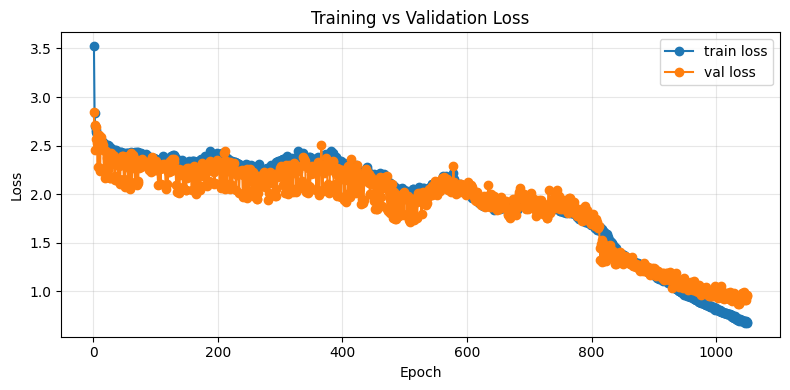

In [ ]:
import json, matplotlib.pyplot as plt
from pathlib import Path

cfg_path = Path(STORAGE_DIR) / "checkpoints/config.json"
if not cfg_path.exists():
    print("No config.json found — train the model first.")
else:
    epoches = json.loads(cfg_path.read_text()).get("epoches", [])
    if not epoches:
        print("No epoch data yet — run the training cell first.")
    else:
        train_losses = [e[0] for e in epoches]
        val_losses = [e[1] for e in epoches]
        xs = range(1, len(epoches) + 1)

        fig, ax = plt.subplots(figsize=(8, 4))
        ax.plot(xs, train_losses, marker="o", label="train loss")
        ax.plot(xs, val_losses, marker="o", label="val loss")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.set_title("Training vs Validation Loss")
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()